In [1]:
import sys
sys.path.append('../src')

from data_loader import load_raw_data
from data_cleaner import clean_pipeline

df = load_raw_data('../data/raw/train.csv')
df_clean = clean_pipeline(df)
print(df_clean.shape)

Veri yüklendi: 9800 satır, 18 sütun
Temizleme pipeline'ı tamamlandı.
(9800, 21)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r'C:\Users\kubra\veri-pipeline-projesi\data\raw\train.csv', encoding='latin-1')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
import sys
sys.path.append('../src')

from data_loader import load_raw_data
from data_cleaner import clean_pipeline, detect_outliers_iqr
from visualizer import plot_sales_overview, plot_outlier_boxplots

In [4]:
print(f"Satır sayısı: {df.shape[0]}")
print(f"Sütun sayısı: {df.shape[1]}")
print(f"\nSütunlar: {df.columns.tolist()}")

Satır sayısı: 9800
Sütun sayısı: 18

Sütunlar: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [5]:
print("Eksik Değerler:")
print(df.isnull().sum())

Eksik Değerler:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [6]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [7]:
# 1. Tarih sütunlarını düzelt (şu an metin olarak okunuyor)
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

# 2. Eksik Postal Code'ları doldur (en sık görülen değerle)
df['Postal Code'] = df['Postal Code'].fillna(df['Postal Code'].median())
df['Postal Code'] = df['Postal Code'].astype(int)

# 3. Yeni sütunlar türet
df['Delivery Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month

# 4. Kontrol et
print("Temizleme sonrası eksik değerler:")
print(df.isnull().sum())
print(f"\nYeni sütunlar eklendi. Toplam sütun: {df.shape[1]}")
df[['Order Date', 'Ship Date', 'Delivery Days', 'Order Year', 'Order Month']].head()

Temizleme sonrası eksik değerler:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Delivery Days    0
Order Year       0
Order Month      0
dtype: int64

Yeni sütunlar eklendi. Toplam sütun: 21


,Order Date,Ship Date,Delivery Days,Order Year,Order Month
0,2017-11-08,2017-11-11,3,2017,11
1,2017-11-08,2017-11-11,3,2017,11
2,2017-06-12,2017-06-16,4,2017,6
3,2016-10-11,2016-10-18,7,2016,10
4,2016-10-11,2016-10-18,7,2016,10


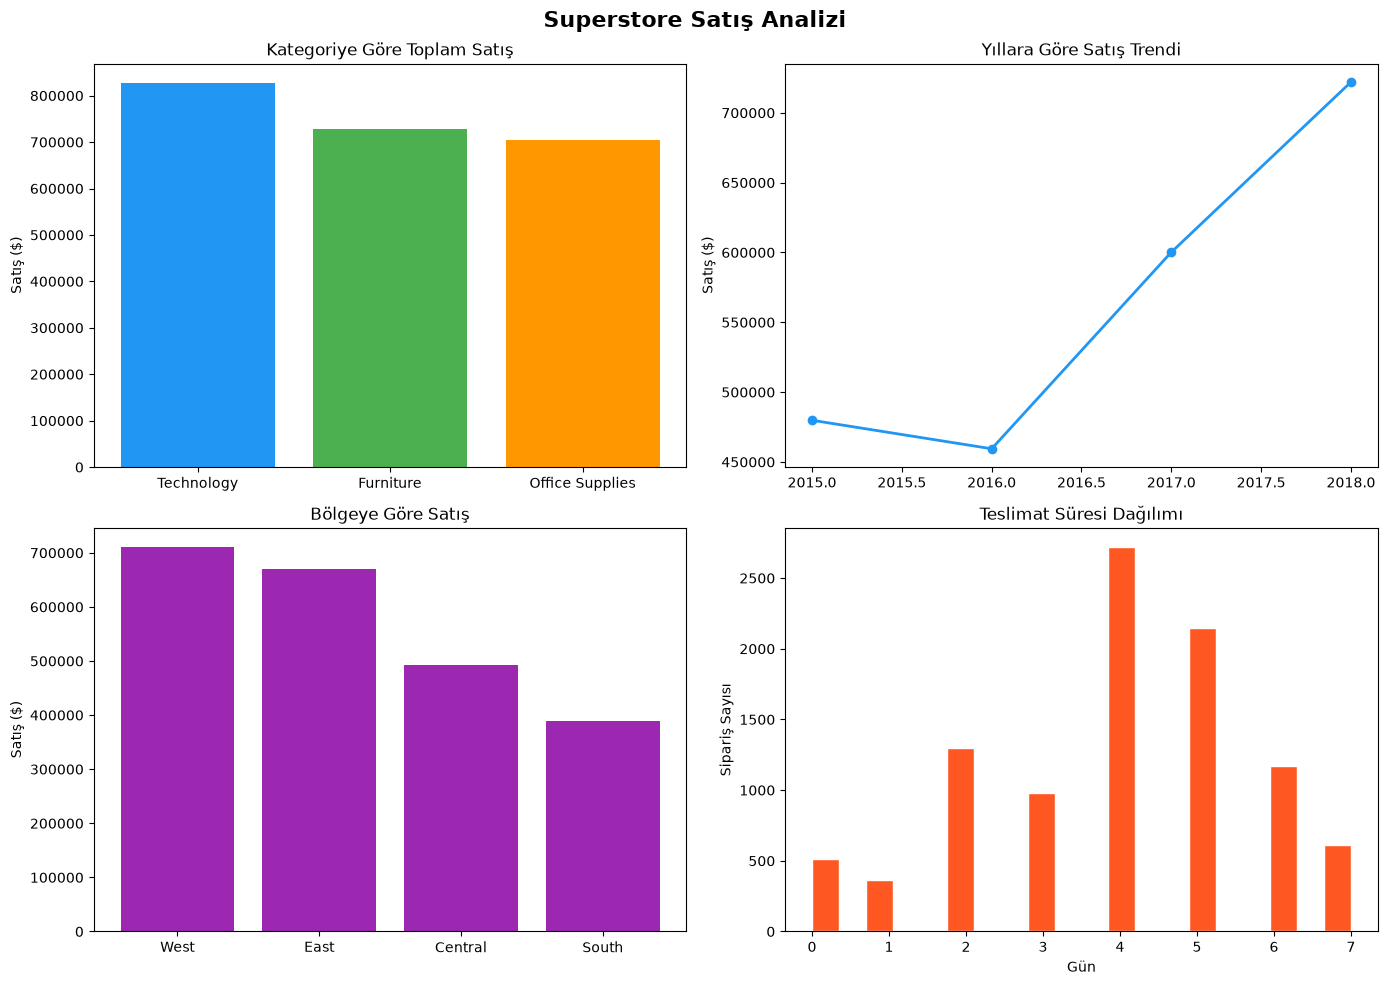

Grafik kaydedildi!


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Superstore Satış Analizi', fontsize=16, fontweight='bold')

# 1. Kategoriye göre satış
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
axes[0,0].bar(category_sales.index, category_sales.values, color=['#2196F3','#4CAF50','#FF9800'])
axes[0,0].set_title('Kategoriye Göre Toplam Satış')
axes[0,0].set_ylabel('Satış ($)')

# 2. Yıllara göre satış trendi
yearly_sales = df.groupby('Order Year')['Sales'].sum()
axes[0,1].plot(yearly_sales.index, yearly_sales.values, marker='o', linewidth=2, color='#2196F3')
axes[0,1].set_title('Yıllara Göre Satış Trendi')
axes[0,1].set_ylabel('Satış ($)')

# 3. Bölgeye göre satış
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
axes[1,0].bar(region_sales.index, region_sales.values, color='#9C27B0')
axes[1,0].set_title('Bölgeye Göre Satış')
axes[1,0].set_ylabel('Satış ($)')

# 4. Teslimat süresi dağılımı
axes[1,1].hist(df['Delivery Days'], bins=20, color='#FF5722', edgecolor='white')
axes[1,1].set_title('Teslimat Süresi Dağılımı')
axes[1,1].set_xlabel('Gün')
axes[1,1].set_ylabel('Sipariş Sayısı')

plt.tight_layout()
plt.savefig(r'C:\Users\kubra\veri-pipeline-projesi\data\processed\analiz_grafikleri.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik kaydedildi!")

In [9]:
# İşlenmiş veriyi kaydet
df.to_csv(r'C:\Users\kubra\veri-pipeline-projesi\data\processed\superstore_temiz.csv', index=False)

print("✓ Temizlenmiş veri kaydedildi!")
print(f"  → data/processed/superstore_temiz.csv")
print(f"  → {df.shape[0]} satır, {df.shape[1]} sütun")
print(f"\nÖzet İstatistikler:")
print(f"  Toplam Satış: ${df['Sales'].sum():,.0f}")
print(f"  Ortalama Sipariş: ${df['Sales'].mean():.2f}")
print(f"  Ortalama Teslimat: {df['Delivery Days'].mean():.1f} gün")
print(f"  En Çok Satan Kategori: {df.groupby('Category')['Sales'].sum().idxmax()}")
print(f"  En İyi Bölge: {df.groupby('Region')['Sales'].sum().idxmax()}")

✓ Temizlenmiş veri kaydedildi!
  → data/processed/superstore_temiz.csv
  → 9800 satır, 21 sütun

Özet İstatistikler:
  Toplam Satış: $2,261,537
  Ortalama Sipariş: $230.77
  Ortalama Teslimat: 4.0 gün
  En Çok Satan Kategori: Technology
  En İyi Bölge: West


In [10]:
# IQR yöntemiyle aykırı değer tespiti
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Sales sütununda aykırı değerleri bul
outliers, lower, upper = detect_outliers_iqr(df, 'Sales')

print(f"Normal aralık: ${lower:.2f} - ${upper:.2f}")
print(f"Aykırı değer sayısı: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")
print(f"\nEn yüksek 5 satış:")
print(outliers.nlargest(5, 'Sales')[['Product Name', 'Category', 'Sales']])

Normal aralık: $-272.79 - $500.64
Aykırı değer sayısı: 1145 (11.7%)

En yüksek 5 satış:
                                           Product Name    Category      Sales
2697  Cisco TelePresence System EX90 Videoconferenci...  Technology  22638.480
6826              Canon imageCLASS 2200 Advanced Copier  Technology  17499.950
8153              Canon imageCLASS 2200 Advanced Copier  Technology  13999.960
2623              Canon imageCLASS 2200 Advanced Copier  Technology  11199.968
4190              Canon imageCLASS 2200 Advanced Copier  Technology  10499.970


C:\Users\kubra\AppData\Local\Temp\ipykernel_11988\3789890343.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(df['Sales'], vert=True)


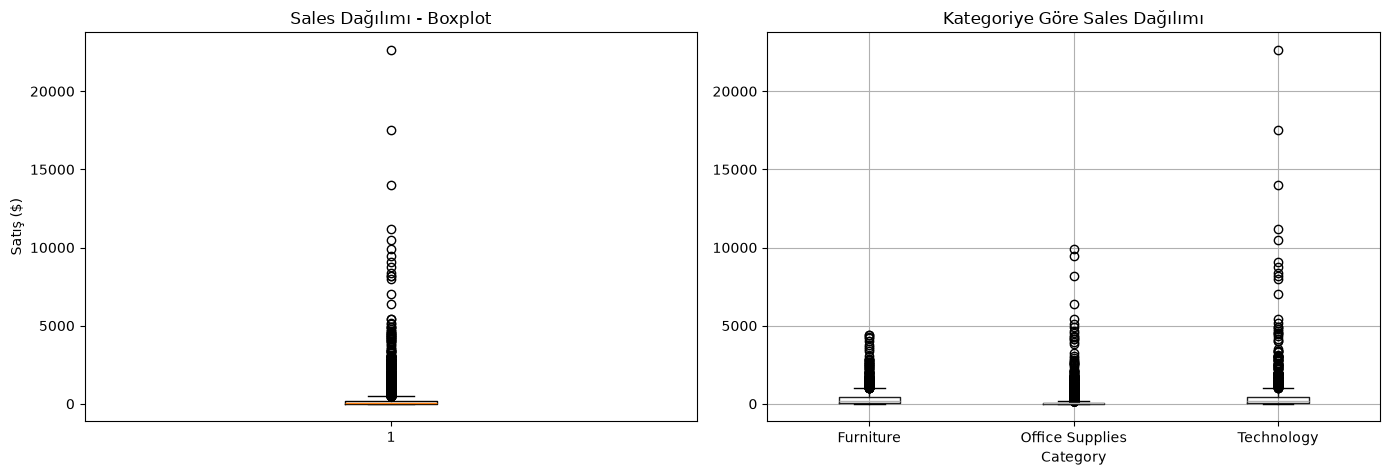

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot - aykırı değerleri görsel olarak gösterir
axes[0].boxplot(df['Sales'], vert=True)
axes[0].set_title('Sales Dağılımı - Boxplot')
axes[0].set_ylabel('Satış ($)')

# Kategoriye göre boxplot
df.boxplot(column='Sales', by='Category', ax=axes[1])
axes[1].set_title('Kategoriye Göre Sales Dağılımı')
plt.suptitle('')

plt.tight_layout()
plt.savefig(r'C:\Users\kubra\veri-pipeline-projesi\data\processed\outlier_analizi.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
import visualizer
print(dir(visualizer))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'matplotlib', 'os', 'plot_outlier_boxplots', 'plot_sales_overview', 'plt', 'sns']


Veri yüklendi: 9800 satır, 18 sütun
Temizleme pipeline'ı tamamlandı.
Aykırı değer: 1145 adet
Grafik kaydedildi: C:\Users\kubra\veri-pipeline-projesi\data\processed\analiz_grafikleri.png


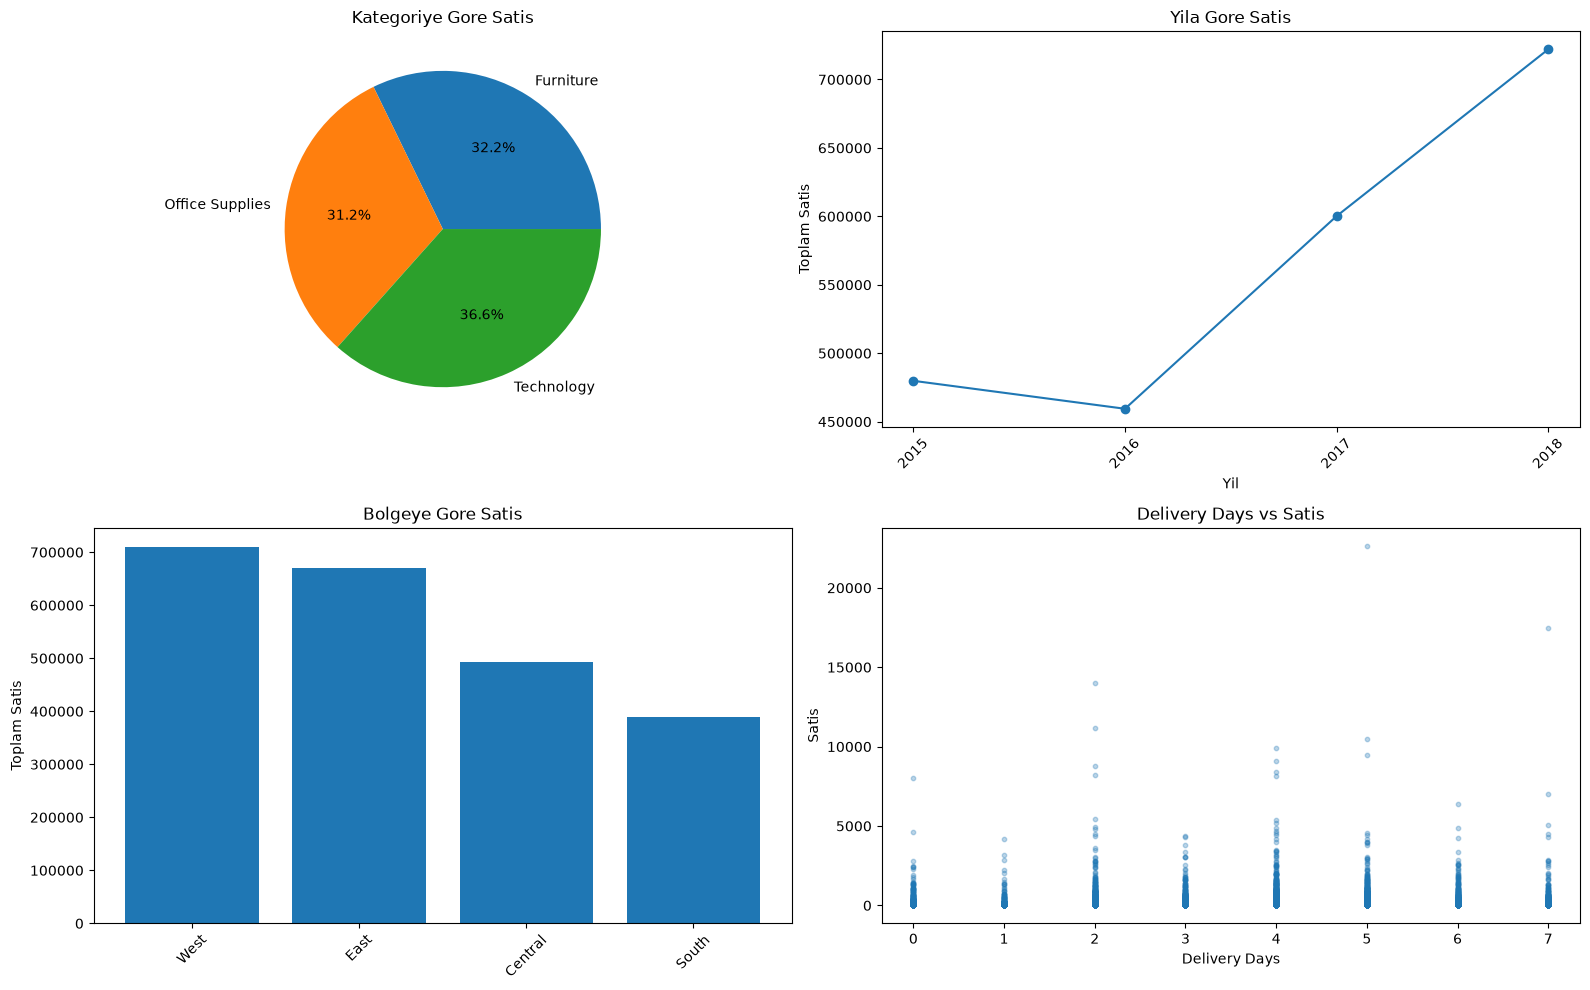

In [13]:
# Baştan, modüler fonksiyonlarla tüm pipeline'ı çalıştır
df = load_raw_data(r'C:\Users\kubra\veri-pipeline-projesi\data\raw\train.csv')
df = clean_pipeline(df)

outliers, lower, upper = detect_outliers_iqr(df, 'Sales')
print(f"Aykırı değer: {len(outliers)} adet")

plot_sales_overview(df, save_path=r'C:\Users\kubra\veri-pipeline-projesi\data\processed\analiz_grafikleri.png')

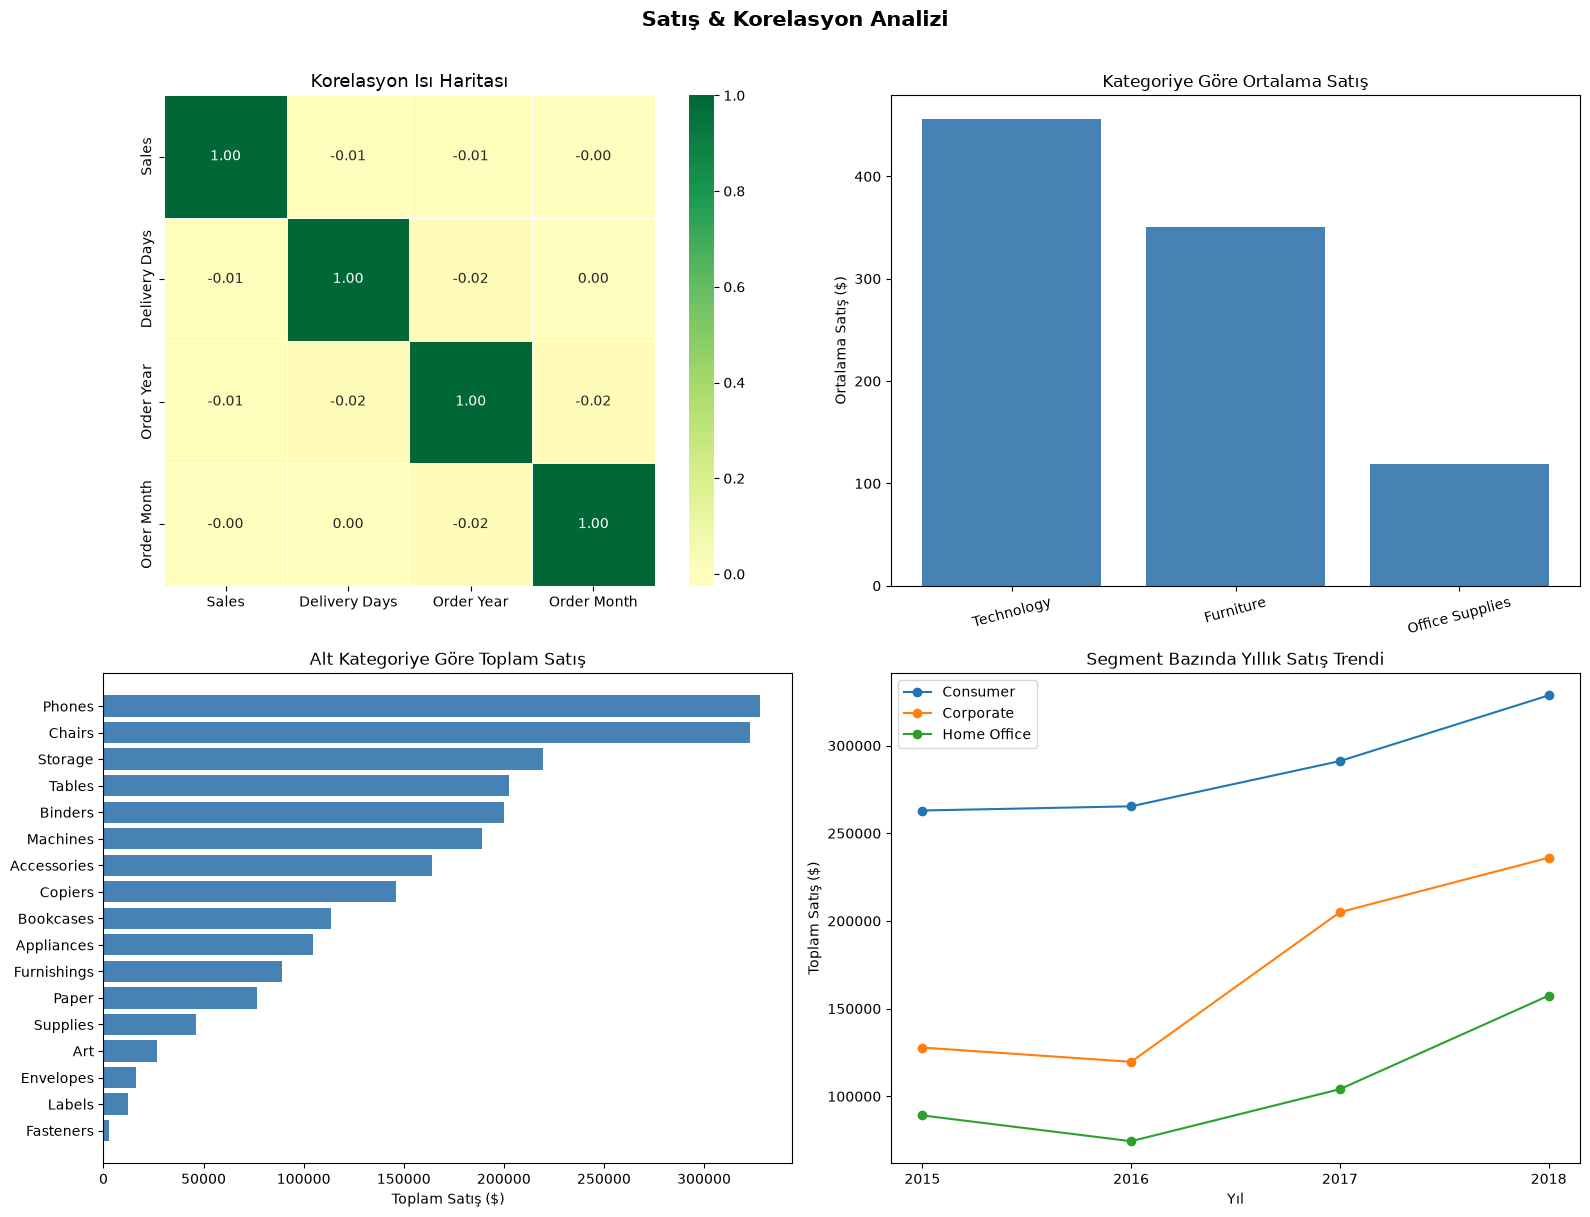


📊 KORELASYON BULGULARI:
  • Delivery Days ↔ Sales: -0.01
  • Order Month ↔ Sales: -0.00

🏆 En çok satan kategori: Technology (ort. $456)
📦 En az satan kategori: Office Supplies (ort. $119)
⭐ En yüksek alt kategori: Phones ($327,782)


In [16]:
# ============================================================
# KORELASYON & SATIŞ ANALİZİ
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Mevcut sayısal kolonlar
num_cols = ['Sales', 'Delivery Days', 'Order Year', 'Order Month']
df_num = df_clean[num_cols].copy()

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))

# 1) Korelasyon ısı haritası
corr = df_num.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5, ax=axes[0, 0])
axes[0, 0].set_title('Korelasyon Isı Haritası', fontsize=13)

# 2) Kategoriye göre ortalama satış
cat_sales = df_clean.groupby('Category')['Sales'].mean().sort_values(ascending=False)
axes[0, 1].bar(cat_sales.index, cat_sales.values, color='steelblue')
axes[0, 1].set_title('Kategoriye Göre Ortalama Satış')
axes[0, 1].set_ylabel('Ortalama Satış ($)')
axes[0, 1].tick_params(axis='x', rotation=15)

# 3) Alt kategoriye göre toplam satış
subcat_sales = df_clean.groupby('Sub-Category')['Sales'].sum().sort_values()
axes[1, 0].barh(subcat_sales.index, subcat_sales.values, color='steelblue')
axes[1, 0].set_title('Alt Kategoriye Göre Toplam Satış')
axes[1, 0].set_xlabel('Toplam Satış ($)')

# 4) Segment bazında yıllık satış trendi
for segment in df_clean['Segment'].unique():
    seg_df = df_clean[df_clean['Segment'] == segment]
    yearly = seg_df.groupby('Order Year')['Sales'].sum()
    axes[1, 1].plot(yearly.index, yearly.values, marker='o', label=segment)
axes[1, 1].set_title('Segment Bazında Yıllık Satış Trendi')
axes[1, 1].set_xlabel('Yıl')
axes[1, 1].set_ylabel('Toplam Satış ($)')
axes[1, 1].legend()
axes[1, 1].set_xticks(df_clean['Order Year'].unique())

plt.suptitle('Satış & Korelasyon Analizi', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../data/processed/korelasyon_analizi.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close('all')

# --- Özet ---
print("\n📊 KORELASYON BULGULARI:")
for col in ['Delivery Days', 'Order Month']:
    print(f"  • {col} ↔ Sales: {corr.loc[col, 'Sales']:.2f}")

print(f"\n🏆 En çok satan kategori: {cat_sales.index[0]} (ort. ${cat_sales.iloc[0]:,.0f})")
print(f"📦 En az satan kategori: {cat_sales.index[-1]} (ort. ${cat_sales.iloc[-1]:,.0f})")

top_subcat = subcat_sales.iloc[-1]
print(f"⭐ En yüksek alt kategori: {subcat_sales.index[-1]} (${top_subcat:,.0f})")

In [17]:
# ============================================================
# OTOMATİK HTML RAPORU
# ============================================================
from report_generator import generate_html_report

rapor_yolu = generate_html_report(df_clean, output_path='../outputs/rapor.html')
print(f"Rapor hazır: {rapor_yolu}")

HTML raporu kaydedildi: ../outputs/rapor.html
Rapor hazır: ../outputs/rapor.html


In [18]:
# ============================================================
# LOGGING TESTİ
# ============================================================
from logger import get_logger

log = get_logger()

log.info("Pipeline baslatildi")
log.info(f"Veri yuklendi: {df_clean.shape[0]} satir, {df_clean.shape[1]} kolon")
log.warning("Dikkat: Bu dataset Profit/Discount kolonlari icermiyor")
log.info("Temizleme asamasi tamamlandi")
log.info("Rapor olusturuldu: outputs/rapor.html")
log.info("Pipeline basariyla tamamlandi")

2026-10-12 15:20:22 | INFO     | veri_pipeline | Pipeline baslatildi
2026-10-12 15:20:22 | INFO     | veri_pipeline | Veri yuklendi: 9800 satir, 21 kolon
2026-10-12 15:20:22 | WARNING  | veri_pipeline | Dikkat: Bu dataset Profit/Discount kolonlari icermiyor
2026-10-12 15:20:22 | INFO     | veri_pipeline | Temizleme asamasi tamamlandi
2026-10-12 15:20:22 | INFO     | veri_pipeline | Rapor olusturuldu: outputs/rapor.html
2026-10-12 15:20:22 | INFO     | veri_pipeline | Pipeline basariyla tamamlandi
